# 02. Zero-shot 변이 점수와 TraitGym — 공개 점수 평가 + NT LLR 직접 계산

**등급**: 🟢 Mac 로컬 (MPS/CPU) · **예상 시간**: 3~6분 · **다운로드**: TraitGym 변이표 + 점수 파일 약 3 MB(MIT), hg38 chr1 약 75 MB(UCSC), NT v1 500M 약 1.9 GB(CC BY-NC-SA, **비상업**)

**질문**
1. 사람 **비코딩 조절 변이**의 인과 후보를 학습 없이 가려내는 데 보존 기반 점수, CADD, DNA 언어모델, 지도 sequence-to-function 모델은 각각 얼마나 쓸모 있는가?
2. **직접 계산한 NT LLR**은 같은 변이에서 어디쯤에 놓이는가? 프레임·방향 평균은 영향이 있는가?

**데이터**: TraitGym `mendelian_traits_matched_9` — 변이 3,380개, 양성(인과 후보) 338개, 양성 1개당 **매칭된 대조 9개**(`match_group`). 양성 비율 0.10이므로 **무작위 예측의 AUPRC ≈ 0.10**.

**규칙: 점수의 부호(방향)는 데이터를 보기 전에 정한다.** 부호를 정답을 보고 고르면 누출이다. 여기서는 "값이 클수록 인과 후보"가 되도록 부호를 **사전에 규정**한다.
- 보존 점수(phyloP, phastCons), CADD, 지도 모델의 변화량(L2), Sei: **+**
- LLR(언어모델): **−** (alt가 ref보다 덜 그럴듯할수록 음수이고, 이를 해로운 변이일 것이라고 가정한다)
- |LLR|: **+**

In [1]:
import gzip
import os
import time
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
if ROOT is not None:
    os.environ.setdefault("HF_HOME", str(ROOT / ".cache" / "hf"))
GENOME_DIR = (ROOT / ".cache" / "genome") if ROOT else Path("genome")
GENOME_DIR.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import torch
from huggingface_hub import hf_hub_download
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score
from transformers import AutoTokenizer, EsmForMaskedLM
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE, "| HF_HOME:", os.environ.get("HF_HOME", "(default)"))

W1110 11:55:42.789000 25753 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | HF_HOME: <repo>/.cache/hf


## 1. TraitGym 변이표와 공개 점수 불러오기
출처: Hugging Face `songlab/TraitGym` (MIT). 점수 파일은 변이표(`test.parquet`)와 **같은 행 순서**다.

In [2]:
TG = "songlab/TraitGym"
D = "mendelian_traits_matched_9"
tg = pd.read_parquet(hf_hub_download(TG, f"{D}/test.parquet", repo_type="dataset"))
y = tg.label.values.astype(int)
print(f"변이 {len(tg)}개 | 양성 {y.sum()} | 양성 비율 {y.mean():.3f} | match_group {tg.match_group.nunique()}개 (그룹당 {tg.groupby('match_group').size().unique().tolist()}개)")
print("그룹이 여러 염색체에 걸치는 수:", int((tg.groupby("match_group").chrom.nunique() > 1).sum()))
print(tg.consequence.value_counts().head(5).to_dict())


def feat(name, col):
    x = pd.read_parquet(hf_hub_download(TG, f"{D}/features/{name}.parquet", repo_type="dataset"))
    return x[col].values.astype(float)


# 이름: (파일, 열, 사전에 정한 부호)
SCORES = {
    "phyloP-241m": ("phyloP-241m", "score", +1),
    "phyloP-100v": ("phyloP-100v", "score", +1),
    "phastCons-43p": ("phastCons-43p", "score", +1),
    "CADD (RawScore)": ("CADD", "RawScore", +1),
    "GPN-MSA LLR": ("GPN-MSA_LLR", "score", -1),
    "GPN-MSA |LLR|": ("GPN-MSA_absLLR", "score", +1),
    "Evo 2 40B LLR": ("evo2_40b_LLR", "score", -1),
    "Evo 2 7B LLR": ("evo2_7b_LLR", "score", -1),
    "Evo 2 1B LLR": ("evo2_1b_base_LLR", "score", -1),
    "NT LLR (TraitGym)": ("NucleotideTransformer_LLR", "score", -1),
    "NT |LLR| (TraitGym)": ("NucleotideTransformer_absLLR", "score", +1),
    "Caduceus LLR": ("Caduceus_LLR", "score", -1),
    "HyenaDNA LLR": ("HyenaDNA_LLR", "score", -1),
    "Enformer L2 (all)": ("Enformer_L2_L2", "all", +1),
    "Borzoi L2 (all)": ("Borzoi_L2_L2", "all", +1),
    "Sei (seqclass_max_absdiff)": ("Sei", "seqclass_max_absdiff", +1),
}
S = {name: sign * feat(f, c) for name, (f, c, sign) in SCORES.items()}
S["TSS 거리만 (가까울수록 +)"] = -tg.tss_dist.abs().values.astype(float)       # 매칭 변수로 만든 점수는 정보가 없어야 한다
print(len(S), "개 점수 준비됨. NaN 있는 점수:", {k: int(np.isnan(v).sum()) for k, v in S.items() if np.isnan(v).any()})

변이 3380개 | 양성 338 | 양성 비율 0.100 | match_group 338개 (그룹당 [10]개)
그룹이 여러 염색체에 걸치는 수: 0
{'5_prime_UTR_variant': 1140, 'non_coding_transcript_exon_variant': 710, 'PLS': 630, '3_prime_UTR_variant': 290, 'upstream_gene_variant': 210}
17 개 점수 준비됨. NaN 있는 점수: {}


## 2. 평가 함수 — AUPRC와 매칭 그룹 단위 부트스트랩
- **AUPRC**: 양성이 드물 때(여기서 10%) 양성을 상위에 놓는 능력을 본다. 무작위 기대값 = 양성 비율.
- **신뢰구간**: 변이 단위가 아니라 **match_group 단위로 재표본**한다 (그룹 안 변이들은 매칭되어 있어 독립이 아니다).
- TraitGym의 주 지표 `AUPRC_by_chrom_weighted_average`는 염색체별 AUPRC의 가중 평균이다. 아래 구현은 변이 수 가중이며 **공식 정의와 다를 수 있다**†.

In [3]:
def auprc_group_ci(y, s, groups, n_boot=300, seed=0):
    ok = ~np.isnan(s)
    y, s, g = y[ok], s[ok], groups[ok]
    ug = np.unique(g)
    idx = {k: np.where(g == k)[0] for k in ug}
    rs = np.random.RandomState(seed)
    vals = []
    for _ in range(n_boot):
        ii = np.concatenate([idx[k] for k in rs.choice(ug, len(ug), replace=True)])
        if y[ii].sum() > 0:
            vals.append(average_precision_score(y[ii], s[ii]))
    return average_precision_score(y, s), *np.percentile(vals, [2.5, 97.5])


def auprc_chrom_weighted(y, s, chrom):
    parts = []
    for c in np.unique(chrom):
        m = (chrom == c) & ~np.isnan(s)
        if y[m].sum() > 0:
            parts.append((average_precision_score(y[m], s[m]), m.sum()))
    w = np.array([p[1] for p in parts], dtype=float)
    return float(np.sum([p[0] * p[1] for p in parts]) / w.sum())


def perm_null(y, groups, score, n_perm=1000, seed=0):
    """이 점수의 *값*을 match_group 안에서 무작위로 섞었을 때의 풀링 AUPRC 분포 (그룹 안에서 정보가 없다는 귀무분포).
    점수마다 따로 만든다: 점수의 전체 분포와 동점 구조가 풀링 AUPRC에 영향을 주므로 공통 귀무분포(예: 순위 0…9)는 관측 통계량의 순열 분포가 아니다.
    부트스트랩 구간은 점수의 표본 변동만 반영하므로 '무작위와 다른가'는 이 귀무분포로 판단한다."""
    ok = ~np.isnan(score)
    y, g, s = y[ok], groups[ok], score[ok]
    base = np.lexsort((np.arange(len(y)), g))                     # 그룹 블록 순서의 인덱스
    rs = np.random.RandomState(seed)
    vals = []
    for _ in range(n_perm):
        shuf = np.lexsort((rs.random_sample(len(y)), g))          # 각 그룹 블록 안의 무작위 순열
        sc = np.empty(len(y))
        sc[base] = s[shuf]
        vals.append(average_precision_score(y, sc))
    return np.array(vals)


def perm_p(obs, null):
    return (1 + np.sum(null >= obs)) / (1 + len(null))


groups, chrom = tg.match_group.values, tg.chrom.values
t0 = time.time()
NULL_ALL = {name: perm_null(y, groups, s, seed=i) for i, (name, s) in enumerate(S.items())}          # 점수마다 1,000회
nm, nq = [v.mean() for v in NULL_ALL.values()], [np.percentile(v, 95) for v in NULL_ALL.values()]
print(f"점수별 귀무분포(그룹 내 점수 값 섞기, 1,000회) AUPRC: 평균 {min(nm):.3f}~{max(nm):.3f}, 95% 분위수 {min(nq):.3f}~{max(nq):.3f}  ← 유한 표본의 무작위 기대값은 양성 비율 0.10과 약간 다를 수 있다 ({time.time() - t0:.0f}s)")
rows = []
for name, s in S.items():
    a, lo, hi = auprc_group_ci(y, s, groups)
    rows.append(dict(score=name, auprc=a, lo=lo, hi=hi, auprc_chrom_w=auprc_chrom_weighted(y, s, chrom), flipped_sign=average_precision_score(y[~np.isnan(s)], -s[~np.isnan(s)])))
res_all = pd.DataFrame(rows).sort_values("auprc", ascending=False).reset_index(drop=True)
res_all["AUPRC [95% CI]"] = res_all.apply(lambda r: f"{r.auprc:.3f} [{r.lo:.3f},{r.hi:.3f}]", axis=1)
res_all["무작위 대비 p"] = [perm_p(a, NULL_ALL[n]) for n, a in zip(res_all.score, res_all.auprc)]
print(f"양성 비율 = {y.mean():.3f} (무작위 AUPRC의 근사 기준)")
print(res_all[["score", "AUPRC [95% CI]", "무작위 대비 p", "auprc_chrom_w", "flipped_sign"]].round(3).to_string(index=False))

점수별 귀무분포(그룹 내 점수 값 섞기, 1,000회) AUPRC: 평균 0.101~0.102, 95% 분위수 0.103~0.113  ← 유한 표본의 무작위 기대값은 양성 비율 0.10과 약간 다를 수 있다 (33s)


양성 비율 = 0.100 (무작위 AUPRC의 근사 기준)
                     score      AUPRC [95% CI]  무작위 대비 p  auprc_chrom_w  flipped_sign
           CADD (RawScore) 0.694 [0.647,0.742]     0.001          0.712         0.055
               GPN-MSA LLR 0.688 [0.634,0.741]     0.001          0.694         0.054
               phyloP-241m 0.673 [0.627,0.718]     0.001          0.696         0.056
               phyloP-100v 0.653 [0.603,0.704]     0.001          0.655         0.056
             GPN-MSA |LLR| 0.649 [0.591,0.705]     0.001          0.654         0.055
             Evo 2 40B LLR 0.534 [0.482,0.589]     0.001          0.557         0.056
             phastCons-43p 0.497 [0.448,0.558]     0.001          0.527         0.058
           Borzoi L2 (all) 0.411 [0.367,0.455]     0.001          0.436         0.061
              Evo 2 7B LLR 0.381 [0.326,0.427]     0.001          0.385         0.065
         Enformer L2 (all) 0.380 [0.338,0.429]     0.001          0.418         0.064
Sei (seqclass_max_abs

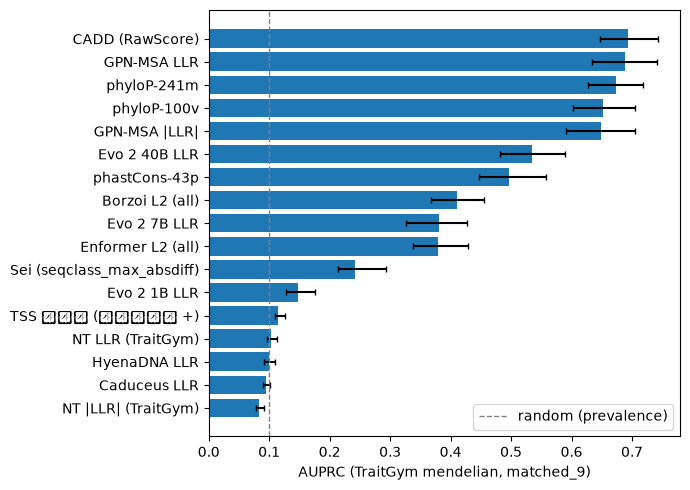

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
r = res_all.iloc[::-1]
ax.barh(r.score, r.auprc, xerr=[r.auprc - r.lo, r.hi - r.auprc], capsize=2)
ax.axvline(y.mean(), color="gray", ls="--", lw=1, label="random (prevalence)")
ax.set_xlabel("AUPRC (TraitGym mendelian, matched_9)")
ax.legend()
plt.tight_layout()
plt.show()

**읽는 법**
- `flipped_sign` 열은 부호를 뒤집었을 때의 AUPRC다. 부호가 맞으면 원래 값보다 훨씬 낮은 것이 정상이다. 부호를 **정답을 본 뒤 고르면** 무작위 근처 점수도 좋아 보이게 만들 수 있다.
- TSS 거리만으로 만든 점수는 매칭 설계 때문에 무작위 기대값 근처여야 한다.
- 모델 크기, 지도/자기지도 구분을 섞어 순위를 단정하지 말고 **보존·CADD 기준선과의 차이**를 본다.

## 3. NT v1 LLR을 직접 계산하기 (chr1 변이만)
**왜 chr1만?** 변이마다 참조 서열 창이 필요하다. 전체 3,380개를 UCSC REST로 조회하면 요청이 너무 많고 염색체 전체를 받으면 약 3 GB다. 승인받은 hg38 **chr1(약 75 MB)**만 쓴다. 그러면 변이가 210개, 양성이 **21개**뿐이라 **통계가 매우 불안정**하다.
**계산**: 변이를 포함하는 600 bp 창을 만들고(NT 학습 길이 1,000토큰 이내), 변이가 속한 6-mer 토큰 **하나를 마스크**해 ref 6-mer와 alt 6-mer의 로그확률 차이를 LLR로 쓴다 (NT는 비겹침 6-mer라 SNV가 정확히 토큰 하나를 바꾼다).
**프레임 평균**: 창 시작을 0~5 nt씩 옮겨 변이가 6-mer 안의 모든 위치에 오도록 6번 계산해 평균한다 (모듈 01의 프레임 이동 민감도). 정방향은 변이의 6-mer 내 위치가 (300−k) mod 6, 역방향은 (299+k) mod 6이라 k=0..5를 돌면 **각각 6개 위치를 모두 한 번씩** 덮는다.
창 길이 W를 바꿔도 동작한다(검증: 120/128/512/600/1024/1200). 단 W가 6의 배수가 아니면 창 **끝**이 단일 염기 토큰이 된다. 변이는 중앙에 있으므로 영향은 없지만 6의 배수가 깔끔하다. **RC 평균**: 창을 reverse complement로 뒤집어 또 6번 계산해 합친다.

In [5]:
CHR1_PATH = GENOME_DIR / "chr1.fa.gz"
CHR1_URL = "https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr1.fa.gz"          # UCSC hg38 chr1, 약 75 MB
if not CHR1_PATH.exists():
    print("downloading", CHR1_URL, "(약 75 MB)")
    urllib.request.urlretrieve(CHR1_URL, CHR1_PATH)
t0 = time.time()
with gzip.open(CHR1_PATH, "rt") as f:
    header = f.readline().strip()
    chr1 = "".join(line.strip() for line in f).upper()
print(header, "| 길이:", f"{len(chr1):,}", f"({time.time() - t0:.0f}s)", "| hg38 chr1 길이(248,956,422)와 일치:", len(chr1) == 248_956_422)

c1 = tg[tg.chrom == "1"].copy()
ok_ref = np.array([chr1[p - 1] == r for p, r in zip(c1.pos, c1.ref)])
print(f"chr1 변이 {len(c1)}개 | 양성 {int(c1.label.sum())} | ref 대립유전자가 참조 서열(pos-1 인덱스)과 일치: {ok_ref.mean():.3f}")

>chr1 | 길이: 248,956,422 (2s) | hg38 chr1 길이(248,956,422)와 일치: True
chr1 변이 210개 | 양성 21 | ref 대립유전자가 참조 서열(pos-1 인덱스)과 일치: 1.000


In [6]:
NT = "InstaDeepAI/nucleotide-transformer-500m-human-ref"
tok = AutoTokenizer.from_pretrained(NT)
mlm = EsmForMaskedLM.from_pretrained(NT).to(DEVICE).eval()
K, W = 6, 600
COMP = str.maketrans("ACGTN", "TGCAN")


@torch.no_grad()
def nt_llr(items, batch=48):
    """items: (창 서열, 창 안 변이 0-based 인덱스, alt 염기)의 리스트 → LLR 배열 (변이가 속한 6-mer 토큰을 마스크)."""
    out = []
    for s in range(0, len(items), batch):
        chunk = items[s:s + batch]
        enc = tok([w for w, _, _ in chunk], return_tensors="pt", padding=True)
        ids = enc["input_ids"].clone()
        t = torch.tensor([v // K + 1 for _, v, _ in chunk])                   # 토큰 인덱스 (0은 <cls>)
        refk = [w[(v // K) * K:(v // K) * K + K] for w, v, _ in chunk]
        altk = [r[:v % K] + a + r[v % K + 1:] for r, (_, v, a) in zip(refk, chunk)]
        ref_id, alt_id = torch.tensor(tok.convert_tokens_to_ids(refk)), torch.tensor(tok.convert_tokens_to_ids(altk))
        ar = torch.arange(len(chunk))
        assert bool((ids[ar, t] == ref_id).all()), "토큰화가 6-mer 경계와 맞지 않음"
        ids[ar, t] = tok.mask_token_id
        lg = mlm(input_ids=ids.to(DEVICE), attention_mask=enc["attention_mask"].to(DEVICE)).logits
        lp = torch.log_softmax(lg[ar.to(DEVICE), t.to(DEVICE)].float(), dim=-1).cpu()
        out.append((lp[ar, alt_id] - lp[ar, ref_id]).numpy())
    return np.concatenate(out)


def windows(chrom_seq, pos1, alt, k, rc):
    c = pos1 - 1
    start = c - W // 2 + k
    if start < 0:
        return "", 0, alt                                       # 염색체 시작 근처는 건너뛴다 (길이 검사에서 걸러진다)
    w = chrom_seq[start:start + W]
    v = c - start
    if rc:                                       # reverse complement: 창을 뒤집고 변이 위치를 W-1-v로 옮기며 alt도 상보 염기로 바꾼다
        w, v, alt = w.translate(COMP)[::-1], W - 1 - v, alt.translate(COMP)
    return w, v, alt


items, meta = [], []
for i, (p, a) in enumerate(zip(c1.pos.values, c1.alt.values)):
    for rc in (False, True):
        for k in range(6):
            w, v, al = windows(chr1, int(p), a, k, rc)
            if len(w) == W and "N" not in w:
                items.append((w, v, al))
                meta.append((i, rc, k))
meta = np.array(meta, dtype=object)
print(f"창 {len(items)}개 (변이 {len(c1)} × 프레임 6 × 방향 2) 계산 시작")
t0 = time.time()
llr = nt_llr(items)
print(f"완료 ({time.time() - t0:.0f}s)")

# 변이별로 집계
M = pd.DataFrame({"i": [m[0] for m in meta], "rc": [m[1] for m in meta], "k": [m[2] for m in meta], "llr": llr})
n_win = M.groupby("i").size()
valid_i = n_win[n_win == 12].index.values
print(f"12개 창(6프레임 × 정/역방향)이 모두 유효한 변이: {len(valid_i)}/{len(c1)} — 제외된 변이는 모든 비교에서 함께 빠진다")
own = {
    "내 NT LLR: 1프레임(정방향)": M[(~M.rc) & (M.k == 0)].set_index("i").llr,
    "내 NT LLR: 6프레임 평균(정방향)": M[~M.rc].groupby("i").llr.mean(),
    "내 NT LLR: 6프레임 × 정/역방향 평균": M.groupby("i").llr.mean(),
}
frame_sd = M[~M.rc].groupby("i").llr.std().mean()
between_sd = own["내 NT LLR: 6프레임 평균(정방향)"].std()
print(f"같은 변이의 프레임 간 LLR 표준편차 평균: {frame_sd:.3f} (프레임을 바꾸면 점수가 이만큼 흔들린다) | 비교: 변이 간 6프레임 평균 LLR의 표준편차 {between_sd:.3f}")

창 2520개 (변이 210 × 프레임 6 × 방향 2) 계산 시작


완료 (83s)
12개 창(6프레임 × 정/역방향)이 모두 유효한 변이: 210/210 — 제외된 변이는 모든 비교에서 함께 빠진다
같은 변이의 프레임 간 LLR 표준편차 평균: 0.619 (프레임을 바꾸면 점수가 이만큼 흔들린다) | 비교: 변이 간 6프레임 평균 LLR의 표준편차 1.311


## 4. chr1에서 비교 — 같은 변이 210개, 양성 21개
직접 계산한 점수는 위 규칙대로 부호 **−**를 적용한다. 공개 점수는 이 변이만 골라 같은 방식으로 평가한다.
표본이 작아 **구간이 매우 넓다**는 점을 먼저 확인한다.

In [7]:
sel = c1.index.values[valid_i]                               # tg의 행 위치 (RangeIndex라 위치 = 라벨). 유효한 변이만
yc, gc = y[sel], groups[sel]
rows, NULL_C1 = [], {}                                        # 점수마다 자기 귀무분포
for name, s in own.items():
    sc = -s.reindex(valid_i).values
    a, lo, hi = auprc_group_ci(yc, sc, gc)
    NULL_C1[name] = perm_null(yc, gc, sc, seed=len(NULL_C1))
    rows.append(dict(score=name, auprc=a, lo=lo, hi=hi))
for name in ["NT LLR (TraitGym)", "GPN-MSA LLR", "Evo 2 7B LLR", "Evo 2 40B LLR", "phyloP-241m", "CADD (RawScore)", "Enformer L2 (all)", "TSS 거리만 (가까울수록 +)"]:
    sc = S[name][sel]
    a, lo, hi = auprc_group_ci(yc, sc, gc)
    NULL_C1["(공개) " + name] = perm_null(yc, gc, sc, seed=len(NULL_C1))
    rows.append(dict(score="(공개) " + name, auprc=a, lo=lo, hi=hi))
res_c1 = pd.DataFrame(rows)
res_c1["AUPRC [95% CI]"] = res_c1.apply(lambda r: f"{r.auprc:.3f} [{r.lo:.3f},{r.hi:.3f}]", axis=1)
res_c1["무작위 대비 p"] = [perm_p(a, NULL_C1[n]) for n, a in zip(res_c1.score, res_c1.auprc)]
nm, nq = [v.mean() for v in NULL_C1.values()], [np.percentile(v, 95) for v in NULL_C1.values()]
print(f"chr1 점수별 귀무분포 AUPRC: 평균 {min(nm):.3f}~{max(nm):.3f}, 95% 분위수 {min(nq):.3f}~{max(nq):.3f}")
print(f"chr1: 변이 {len(sel)}, 양성 {yc.sum()} → 양성 비율 {yc.mean():.3f}")
print(res_c1[["score", "AUPRC [95% CI]", "무작위 대비 p"]].round(3).to_string(index=False))

best_own = -own["내 NT LLR: 6프레임 × 정/역방향 평균"].reindex(valid_i).values
rho_pub = spearmanr(best_own, S["NT LLR (TraitGym)"][sel], nan_policy="omit").statistic
print(f"\n내 NT LLR(6프레임×정/역) vs TraitGym 공개 NT LLR의 Spearman: {rho_pub:.2f} — 다른 모델/창/계산 방식이라 다를 수 있다†")

chr1 점수별 귀무분포 AUPRC: 평균 0.103~0.123, 95% 분위수 0.105~0.187
chr1: 변이 210, 양성 21 → 양성 비율 0.100
                    score      AUPRC [95% CI]  무작위 대비 p
      내 NT LLR: 1프레임(정방향) 0.158 [0.106,0.278]     0.109
   내 NT LLR: 6프레임 평균(정방향) 0.132 [0.091,0.229]     0.289
내 NT LLR: 6프레임 × 정/역방향 평균 0.137 [0.095,0.230]     0.273
   (공개) NT LLR (TraitGym) 0.177 [0.105,0.338]     0.063
         (공개) GPN-MSA LLR 0.442 [0.293,0.675]     0.001
        (공개) Evo 2 7B LLR 0.389 [0.243,0.588]     0.001
       (공개) Evo 2 40B LLR 0.360 [0.248,0.504]     0.001
         (공개) phyloP-241m 0.419 [0.283,0.654]     0.001
     (공개) CADD (RawScore) 0.413 [0.260,0.595]     0.001
   (공개) Enformer L2 (all) 0.309 [0.198,0.486]     0.001
   (공개) TSS 거리만 (가까울수록 +) 0.103 [0.102,0.119]     0.369

내 NT LLR(6프레임×정/역) vs TraitGym 공개 NT LLR의 Spearman: 0.87 — 다른 모델/창/계산 방식이라 다를 수 있다†


## 5. 해석 가이드와 한계
이 실행에서 읽은 내용이다. **표를 직접 확인한다.**
"무작위 대비 p"는 **점수마다** 그 점수의 값을 match_group 안에서 무작위로 섞은 1,000회의 풀링 AUPRC 분포(귀무분포)와 비교한 값이며 최솟값은 약 0.001이다. 몬테카를로 표준오차는 p ≈ 0.4에서 약 0.015이므로 소수 둘째 자리는 시드에 따라 흔들린다.
**부트스트랩 구간이 0.10을 포함하는지로 "무작위와 같다/다르다"를 판단하면 안 된다.** 구간은 점수의 표본 변동만 반영하고 귀무분포와 비교하지 않는다.

**전체 변이 3,380개 (공개 점수; 점수별 귀무분포 평균 0.101~0.102, 95% 분위수 0.103~0.113)**
- **보존·CADD 기준선이 강하다**: CADD 0.69, GPN-MSA LLR 0.69, phyloP-241m 0.67, phyloP-100v 0.65 — 모두 무작위의 6~7배이고 p ≈ 0.001이다. 서로의 구간은 겹치므로 이들 사이의 순위는 단정하기 어렵다.
- **Evo 2는 규모에 따라 오른다**: 1B 0.15, 7B 0.38, 40B 0.53이다. 40B도 CADD·GPN-MSA·phyloP보다 낮다.
- **NT·HyenaDNA·Caduceus(TraitGym 점수)는 무작위와 구별되지 않았다**: AUPRC 0.103 / 0.100 / 0.094, 순열 p = 0.41 / 0.63 / 0.93. NT |LLR|은 0.084로 귀무분포보다도 낮다(p = 1.00). TraitGym이 쓴 모델 변형, 창 길이, 계산 세부는 문서에서 확인해야 한다†.
- **지도 모델**: Borzoi 0.41, Enformer 0.38, Sei 0.24로 일부 DNA LM보다 높고 보존·CADD보다 낮다. 학습 목적이 다르므로 범용 우열이 아니라 **이 변이 집합과 이 지표에서의 비교**로만 읽는다.
- **부호는 사전에 정해야 한다**: 좋은 점수는 부호를 뒤집으면 0.05~0.08로 곤두박질친다. 그런데 NT |LLR|은 원래 0.084(무작위 아래)이고 뒤집으면 0.126(무작위 위)이다. 무작위에 가까운 점수는 부호를 정답을 보고 고르면 좋아 보일 수 있으므로 `flipped_sign` 열은 **진단용**으로만 본다.
- **매칭은 정보를 완전히 없애지 않았다**: TSS 거리만으로 만든 점수는 0.115로 무작위에 가깝지만 p = 0.001(최솟값)로 귀무분포보다 유의하게 높다. 원인(매칭 방식, 표본 등)은 확정하지 말고 관찰로만 기록한다.

**chr1 부분집합 (변이 210개, 양성 21개; 점수별 귀무분포 평균 0.103~0.123, 95% 분위수 0.105~0.187)**
- **직접 계산한 NT LLR**: 1프레임 0.158 (p = 0.109), 6프레임 평균 0.132 (p = 0.289), 6프레임×정/역방향 0.137 (p = 0.273)이며 셋 다 p > 0.1이다. 세 가지를 보고도 다중 비교를 보정하지 않았고 양성이 21개뿐이라 **"무작위보다 낫다/아니다"를 결론낼 수 없다**. 프레임·방향 평균이 점수를 올리지는 않았다.
- **같은 점수가 부분집합에 따라 달라진다**: 공개 NT LLR은 chr1에서 0.177 (p = 0.063)인데 전체 3,380개에서는 0.103 (p = 0.41)이다. 소표본 변동의 전형적인 사례다.
- GPN-MSA 0.44, phyloP 0.42, CADD 0.41, Evo 2 7B 0.39 / 40B 0.36 (모두 p ≈ 0.001)이지만 구간이 넓게 겹친다. 전체에서는 40B > 7B였으나 chr1에서는 7B(0.389)가 40B(0.360)보다 높아 순위가 쉽게 뒤집힌다.
- 내 NT LLR과 공개 NT LLR의 Spearman은 0.87이라 같은 방향의 신호를 본다.
- 같은 변이의 LLR이 프레임에 따라 흔들리는 폭은 변이 간 표준편차의 약 절반이다(위 출력). 프레임을 옮기면 창의 경계와 문맥도 함께 바뀌므로 토큰 프레임 효과와 문맥 변화가 섞인 **관찰된 점수 변동**이다(과제 2).

**한계**
- 직접 계산은 chr1 변이 210개(양성 21개)뿐이다. 신뢰구간이 넓어 모델 간 순위를 가를 수 없다. 과제 2에서 다른 염색체를 추가한다.
- 공개 점수는 TraitGym이 계산한 값이다. 창 길이·방향 처리·모델 변형은 TraitGym 문서에서 확인한다†.
- NT v1 500M(사람 참조만 학습)은 다종/더 큰 모델과 다르다.
- 이 벤치마크는 **멘델 형질의 비코딩 변이**다. 복합 형질(`complex_traits`)이나 코딩 변이로 일반화하지 않는다.
- 과제: [../exercises.md](../exercises.md) 과제 2, 3.